In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
f = np.sin
F = lambda x: -np.cos(x)

In [3]:
a, b = 0, np.pi
n_max = 20
I = F(b) - F(a) # Exaktes Integral

In [4]:
def trapez_sum(f, a, b, n):

    c = np.linspace(a, b, n + 1) # Stützstellen

    w = np.ones(n + 1)           # Gewichte
    if (n > 1):
        w[1:-1] *= 2
        
    return np.sum(f(c) * w) / 2 * (b - a) / n


Text(0.5, 1.0, 'Fehler unterschiedlicher Quadraturmethoden')

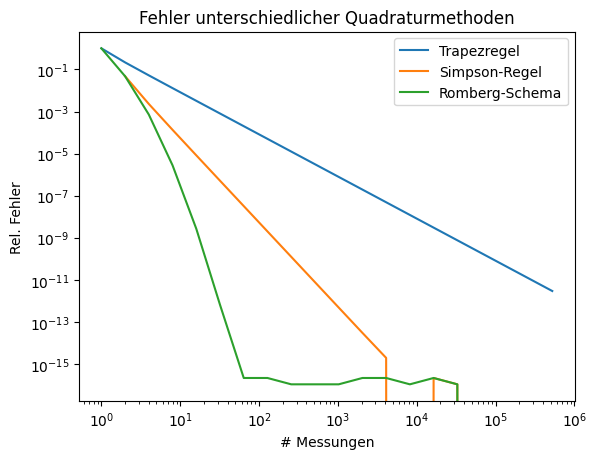

In [6]:
k = np.arange(n_max)
h = 2**k

# Trapezregel
T = np.array([trapez_sum(f, a, b, n) for n in h])

# Simpson-Regel
#   Wir nutzen hier, dass die zweize Spalte des Romberg-Schemas 
#   genau der Simpson-Regel entspricht
S = (4*T[1:] - T[1-1:n_max-1]) / 3

# Romberg-Schema
R = T.copy()
for i in range(1, n_max):
    fac = 4**i
    R[i:] = (fac*R[i:] - R[i-1:n_max-1]) / (fac - 1)

err_rel_T = np.abs(I - T) / I
err_rel_S = np.abs(I - S) / I
err_rel_R = np.abs(I - R) / I
plt.loglog(h, err_rel_T, label="Trapezregel")
plt.loglog(h[1:], err_rel_S, label="Simpson-Regel")
plt.loglog(h, err_rel_R, label="Romberg-Schema")
plt.xlabel("# Messungen")
plt.ylabel("Rel. Fehler")
plt.legend()
plt.title("Fehler unterschiedlicher Quadraturmethoden")